## Practical 08: Customer Segmentation

### Aim
Group customers by age, annual income and spending score without predefined labels.

### Model
K-Means Clustering

### Data
450 generated customers from three overlapping profiles. Income is in thousands of currency units; spending score ranges from 1 to 100.

### Theory
K-Means minimizes within-cluster squared distance. Features are standardized, candidate values of k are compared by silhouette score, and centres are converted back to original units for interpretation.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Silhouette is an internal measure computed on the same data used for clustering. Cluster numbers are arbitrary, not externally verified customer categories.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


In [1]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)


Silhouette by k: {2: 0.424, 3: 0.506, 4: 0.4, 5: 0.322, 6: 0.233}
Selected k: 3
Cluster sizes: [142 156 152]
Centres in original units:
  age  annual_income  spending_score
44.74          90.89           64.52
55.11          50.24           26.17
25.45          34.74           74.72


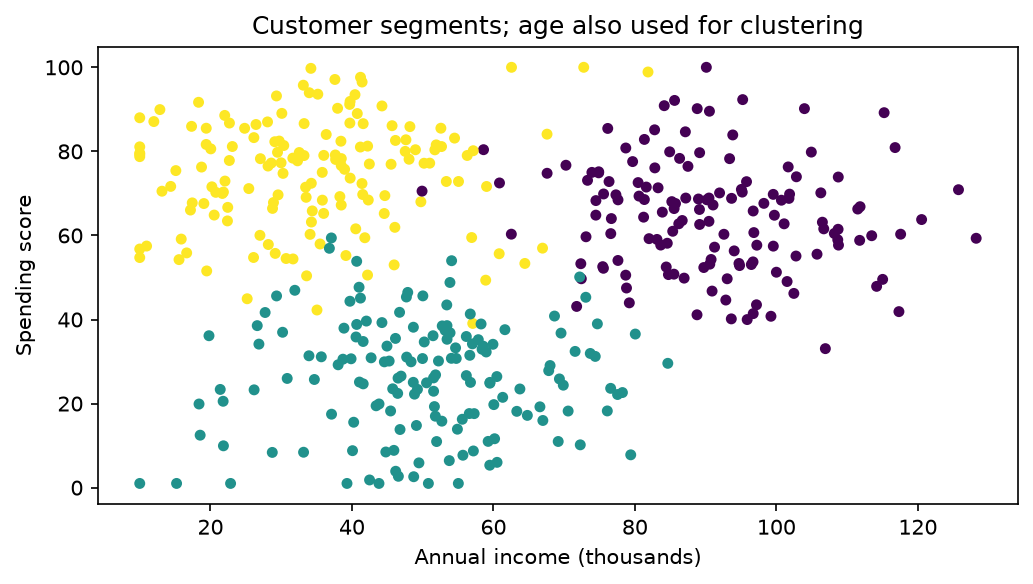

In [3]:
centres = [[25, 35, 75], [45, 90, 65], [55, 50, 25]]
parts = [rng.normal(c, [8, 15, 14], size=(150, 3)) for c in centres]
X = pd.DataFrame(np.vstack(parts), columns=['age', 'annual_income', 'spending_score'])
X['age'] = X.age.clip(18, 80)
X['annual_income'] = X.annual_income.clip(10, 160)
X['spending_score'] = X.spending_score.clip(1, 100)
scaler = StandardScaler()
Z = scaler.fit_transform(X)
candidates = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    candidates[k] = (silhouette_score(Z, km.labels_), km)
best_k = max(candidates, key=lambda k: candidates[k][0])
score, model = candidates[best_k]
print('Silhouette by k:', {k: round(v[0], 3) for k, v in candidates.items()})
print('Selected k:', best_k)
print('Cluster sizes:', np.bincount(model.labels_))
print('Centres in original units:')
print(pd.DataFrame(scaler.inverse_transform(model.cluster_centers_),
                   columns=X.columns).round(2).to_string(index=False))
plt.scatter(X.annual_income, X.spending_score, c=model.labels_, cmap='viridis', s=18)
plt.xlabel('Annual income (thousands)'); plt.ylabel('Spending score')
plt.title('Customer segments; age also used for clustering')
plot_save('08_customer_segments')
metrics = {'selected_k': best_k, 'silhouette': score}

### Result and conclusion
Measured results: selected_k = 3.0000; silhouette = 0.5063. Silhouette is an internal measure computed on the same data used for clustering. Cluster numbers are arbitrary, not externally verified customer categories.